# DAT305: Mandatory Assignment

### Project 1: Explainable Machine Learning for Gallstone Disease

**Research question:** How accurately can a machine learning model distinguish between patients with and without gallstone disease, and which clinical characteristics contribute most to its predictions?

We use XGBoost to classify existing gallstone status from clinical measurements and SHAP to explain the predicted probability of gallstones. Logistic regression provides a simple comparison. The goal is not to predict future disease or provide a clinical diagnosis.

## Class-label definitions

The dataset uses the following encodings:

- Gallstone Status: 0 = Yes,  1 = No (target variable)
- Gender: 0 = Male, 1 = Female 
- Comorbidity: 0 = No comorbidities present, 1 = One comorbid condition, 2 = Two comorbid conditions, 3 = Three or more comorbid conditions 
- Coronary Artery Disease (CAD): 0 = No, 1 = Yes 
- Hypothyroidism: 0 = No, 1 = Yes 
- Hyperlipidemia: 0 = No, 1 = Yes 
- Diabetes Mellitus (DM): 0 = No, 1 = Yes 
- Hepatic Fat Accumulation (HFA): 0 = No fat accumulation, 1 = Grade 1 (mild), 2 = Grade 2 (moderate), 3 = Grade 3 (severe), 4 = Grade 4 (very severe) 

Because Gallstone Status = 1, means No gallstones, evaluation metrics using the default positive class describe performance for the no-gallstone class.

## Gallstone disease prediction

This notebook uses patient health data to predict whether gallstones are present. The main model is XGBoost. The notebook also uses charts and SHAP explanations to show which features affect the predictions.

The aim is to build a useful classification example and to make the model results easier to understand.

## Dataset

The data comes from the UCI Gallstone-1 dataset. It contains 319 patient records and 38 predictor columns. The columns include demographic information, body measurements, medical conditions, hepatic fat accumulation, and laboratory results.

The dataset is loaded from `data/dataset-uci/dataset-uci.csv`. The class definitions above are kept visible because the numeric values have a specific medical meaning.

## Notebook workflow

The notebook is organised into these steps:

1. Import the Python libraries used by the project.
2. Load and preprocess the dataset.
3. Separate the target column from the predictor columns.
4. Split the data into training and test sets.
5. Train the XGBoost classifier and calculate evaluation metrics.
6. Create graphs and SHAP explanations for the model.


In [138]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap

from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    make_scorer, ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

print("NumPy:", np.__version__)
print("XGBoost:", xgb.__version__)
print("SHAP:", shap.__version__)

NumPy: 1.26.4
XGBoost: 3.4.2
SHAP: 0.48.0


## Loading and processing the data

The UCI documentation reports 319 patients, 38 predictors and no missing values. We check this rather than assuming it. Numeric labels are retained. XGBoost does not need feature scaling; logistic regression is scaled later using training data only. Missing rows are removed if present; report the number removed. Exact duplicate rows are reported, not automatically deleted, because there is no patient ID to establish that they are duplicate patients.

In [139]:
def load_data(filename):
    """Load, clean and check the dataset."""
    data = pd.read_csv(filename)
    data.columns = data.columns.str.strip()
    print("Missing values before cleaning:", data.isna().sum().sum())

    cleaned = data.dropna().apply(pd.to_numeric)
    print("Rows removed:", len(data) - len(cleaned))

    if not np.isfinite(cleaned.to_numpy()).all():
        raise ValueError("Dataset contains infinite or missing values.")
    if set(cleaned["Gallstone Status"].unique()) != {0, 1}:
        raise ValueError("Expected both target classes: 0 and 1.")

    return cleaned

## Dataset loader

In [140]:
data = load_data("data/dataset-uci/dataset-uci.csv")
print("Dataset shape:", data.shape)
print("Missing values:", data.isna().sum().sum())
print("Exact duplicate rows:", data.duplicated().sum())
print("Predictors:", data.shape[1] - 1)
display(data.head())

Missing values before cleaning: 0
Rows removed: 0
Dataset shape: (319, 39)
Missing values: 0
Exact duplicate rows: 0
Predictors: 38


,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6


## 3. Exploratory data analysis
We first examine class balance, age and relationships between features. The correlation matrix is descriptive: it does not show causal effects or model importance. The existing model settings are fixed; these plots are not used to select features or tune the model.

In [141]:
def save_plot(filename):
    """Save the current figure and display it."""
    plt.savefig(results_dir / filename, dpi=180, bbox_inches="tight")
    plt.show()

Gallstones: 161 (50.5%); No gallstones: 158 (49.5%)
Age: median 49.0; range 20–96 years.


,count,mean,median,min,max
Gallstone Status,,,,,
0,161,47.63,49.0,20,96
1,158,48.51,50.0,20,76


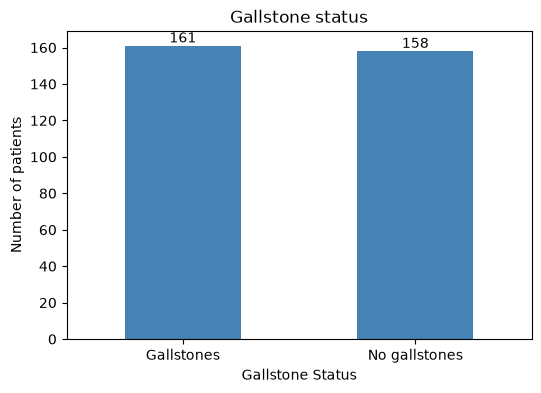

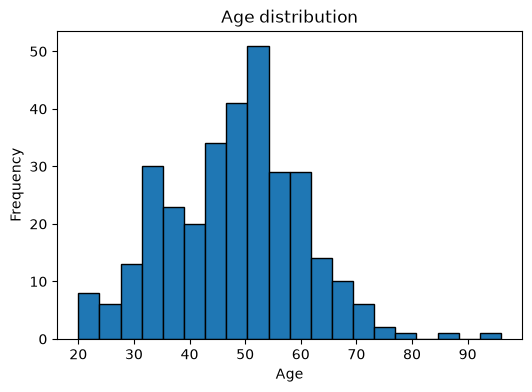

Five strongest absolute Pearson correlations between predictors:


Correlation
Total Body Fat Ratio (TBFR) (%) Lean Mass (LM) (%)              -0.994
Total Body Water (TBW)          Muscle Mass (MM)                 0.929
                                Extracellular Water (ECW)        0.904
Intracellular Water (ICW)       Muscle Mass (MM)                 0.904
Body Mass Index (BMI)           Total Fat Content (TFC)          0.903

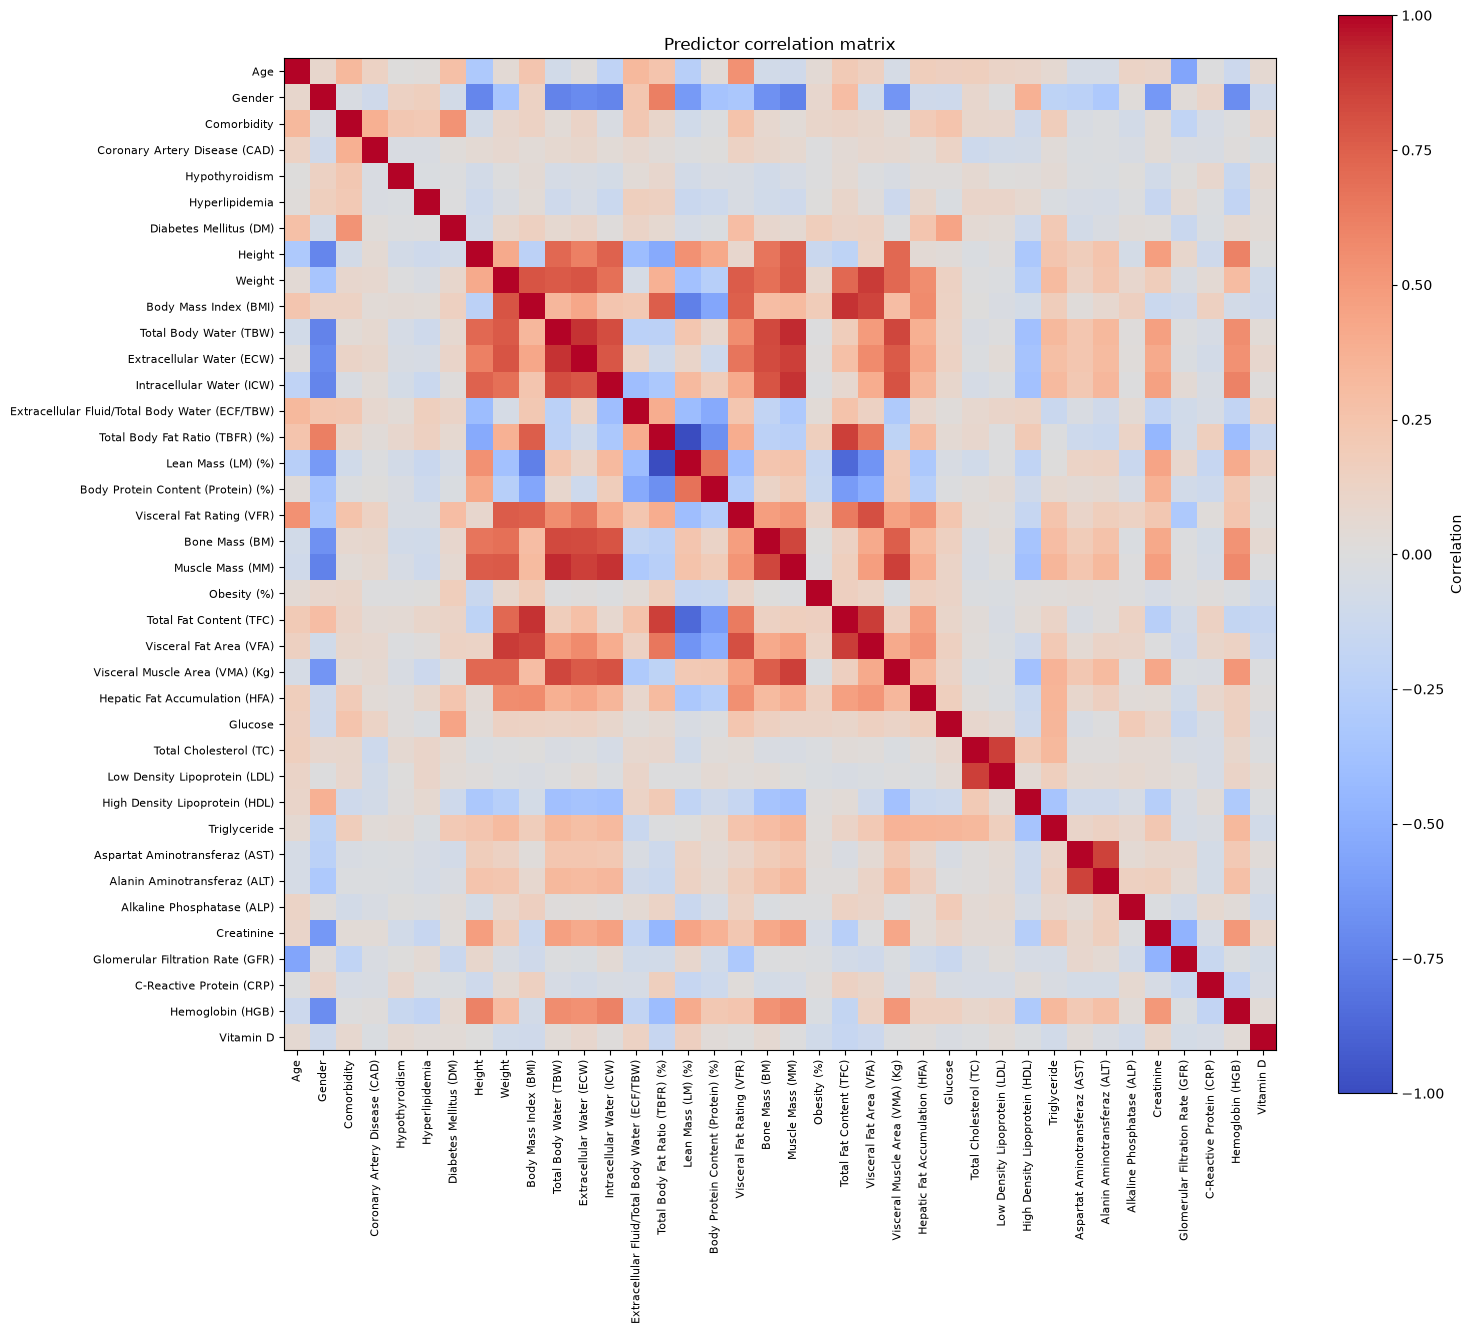

In [142]:
target = data["Gallstone Status"]
features = data.drop(columns="Gallstone Status")
counts = target.value_counts().sort_index()

print(f"Gallstones: {counts[0]} ({counts[0]/len(target):.1%}); "
      f"No gallstones: {counts[1]} ({counts[1]/len(target):.1%})")
print(f"Age: median {data['Age'].median():.1f}; "
      f"range {data['Age'].min()}–{data['Age'].max()} years.")
display(data.groupby("Gallstone Status")["Age"].agg(
    ["count", "mean", "median", "min", "max"]).round(2))

# Class distribution and age histogram
ax = counts.rename(index={0: "Gallstones", 1: "No gallstones"}).plot.bar(
    figsize=(6, 4), rot=0, color="steelblue")
ax.set(title="Gallstone status", ylabel="Number of patients")
ax.bar_label(ax.containers[0])
save_plot("target_distribution.png")

data["Age"].plot.hist(bins=20, figsize=(6, 4), edgecolor="black")
plt.xlabel("Age")
plt.title("Age distribution")
save_plot("age_distribution.png")

# Predictor correlations (exclude the target).
corr = features.corr()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
strong_pairs = upper.reindex(upper.abs().nlargest(5).index)
print("Five strongest absolute Pearson correlations between predictors:")
display(strong_pairs.rename("Correlation").to_frame().round(3))

fig, ax = plt.subplots(figsize=(16, 14))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
ax.set_title("Predictor correlation matrix")
fig.colorbar(image, ax=ax, label="Correlation")
save_plot("correlation_matrix.png")

### EDA interpretation
The earlier saved notebook shows 161 cases and 158 controls, so the dataset is nearly balanced; accuracy is informative but sensitivity and specificity remain important. The age histogram is concentrated around middle adulthood, with relatively few very old patients. The correlation table above quantifies redundancy between clinical measurements; correlated variables can share predictive information and SHAP importance. Check the printed values on this run. Pearson correlation treats numeric category codes as ordered numbers, so interpret such correlations cautiously.

## 4. Model training and evaluation
XGBoost combines boosted decision trees, allowing nonlinear relationships and interactions [2]. We keep the existing settings (100 trees, depth 4, learning rate 0.1, random seed 42). The 80/20 stratified split gives both models the same held-out patients. Class 0 is the clinical positive class. Logistic regression is a simple linear baseline; a scaler fitted within its pipeline prevents leakage.

In [143]:
def gallstone_probability(model, X):
    """Return the predicted probability of class 0 (gallstones)."""
    return model.predict_proba(X)[:, list(model.classes_).index(0)]


def evaluate(model, X, y):
    """Calculate metrics with gallstones as the positive class."""
    predictions = model.predict(X)
    metrics = {
        "accuracy": accuracy_score(y, predictions),
        "precision_gallstones": precision_score(y, predictions, pos_label=0, zero_division=0),
        "sensitivity_gallstones": recall_score(y, predictions, pos_label=0, zero_division=0),
        "specificity_gallstones": recall_score(y, predictions, pos_label=1, zero_division=0),
        "f1_gallstones": f1_score(y, predictions, pos_label=0, zero_division=0),
        "roc_auc_gallstones": roc_auc_score(y == 0, gallstone_probability(model, X))
    }

    print(classification_report(y, predictions, labels=[0, 1],
                                target_names=["Gallstones", "No gallstones"],
                                zero_division=0))
    print("Confusion matrix (rows = actual; columns = predicted):")
    print(confusion_matrix(y, predictions, labels=[0, 1]))
    return metrics

In [144]:
X_train, X_test, y_train, y_test = train_test_split(
    features, target, test_size=0.2, random_state=42, stratify=target
)
print("Training set shape:", X_train.shape, "Test set shape:", X_test.shape)

model = xgb.XGBClassifier(
    objective="binary:logistic", eval_metric="logloss",
    n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42
)
model.fit(X_train, y_train)
metrics = evaluate(model, X_test, y_test)

Training set shape: (255, 38) Test set shape: (64, 38)
               precision    recall  f1-score   support

   Gallstones       0.75      0.94      0.83        32
No gallstones       0.92      0.69      0.79        32

     accuracy                           0.81        64
    macro avg       0.83      0.81      0.81        64
 weighted avg       0.83      0.81      0.81        64

Confusion matrix (rows = actual; columns = predicted):
[[30  2]
 [10 22]]


In [145]:
baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42))
baseline.fit(X_train, y_train)
baseline_metrics = evaluate(baseline, X_test, y_test)

models = {"XGBoost": model, "Logistic regression": baseline}
comparison = pd.DataFrame([metrics, baseline_metrics], index=models.keys())
display(comparison.round(3))

               precision    recall  f1-score   support

   Gallstones       0.76      0.81      0.79        32
No gallstones       0.80      0.75      0.77        32

     accuracy                           0.78        64
    macro avg       0.78      0.78      0.78        64
 weighted avg       0.78      0.78      0.78        64

Confusion matrix (rows = actual; columns = predicted):
[[26  6]
 [ 8 24]]


,accuracy,precision_gallstones,sensitivity_gallstones,specificity_gallstones,f1_gallstones,roc_auc_gallstones
XGBoost,0.812,0.750,0.938,0.688,0.833,0.850
Logistic regression,0.781,0.765,0.812,0.750,0.788,0.883


In [146]:
baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42))
baseline.fit(trainer.X_train, trainer.y_train)
baseline_metrics = trainer.evaluate(baseline)

comparison = pd.DataFrame({"XGBoost": metrics, "Logistic regression": baseline_metrics}).T
comparison = comparison[["accuracy", "precision_gallstones", "sensitivity_gallstones", "specificity_gallstones", "f1_gallstones", "roc_auc_gallstones"]]
display(comparison.round(3))


Classification report (0 = Gallstones, 1 = No gallstones):
               precision    recall  f1-score   support

   Gallstones       0.76      0.81      0.79        32
No gallstones       0.80      0.75      0.77        32

     accuracy                           0.78        64
    macro avg       0.78      0.78      0.78        64
 weighted avg       0.78      0.78      0.78        64


Confusion matrix (rows = actual; columns = predicted; order = [0, 1]):
[[26  6]
 [ 8 24]]


,accuracy,precision_gallstones,sensitivity_gallstones,specificity_gallstones,f1_gallstones,roc_auc_gallstones
XGBoost,0.812,0.750,0.938,0.688,0.833,0.850
Logistic regression,0.781,0.765,0.812,0.750,0.788,0.883


## 5. Five-fold cross-validation
We use five stratified folds on the 255 training patients only (with the test set left untouched). Each fold fits a fresh model; logistic regression fits its scaler within each fold. Mean and sample standard deviation show how performance varies between validation folds. This is not a confidence interval or external validation. The held-out results remain the final test; no model is tuned on them.

In [147]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "accuracy": "accuracy",
    "sensitivity": make_scorer(recall_score, pos_label=0, zero_division=0),
    "specificity": make_scorer(recall_score, pos_label=1, zero_division=0),
    "f1": make_scorer(f1_score, pos_label=0, zero_division=0),
    "roc_auc": "roc_auc"
}

# cross_validate automatically fits a fresh model for each fold.
cv_rows = []
for name, estimator in models.items():
    scores = cross_validate(estimator, X_train, y_train, cv=cv,
                            scoring=scoring, error_score="raise")
    for metric in scoring:
        values = scores[f"test_{metric}"]
        cv_rows.append([name, metric, values.mean(), values.std(ddof=1)])

cv_results = pd.DataFrame(cv_rows, columns=["Model", "Metric", "Mean", "SD"])
display(cv_results.round(3))

,Model,Metric,Mean,SD
0,XGBoost,accuracy,0.761,0.073
1,XGBoost,sensitivity,0.791,0.079
2,XGBoost,specificity,0.730,0.085
3,XGBoost,f1,0.770,0.069
4,XGBoost,roc_auc,0.834,0.079
5,Logistic regression,accuracy,0.741,0.082
6,Logistic regression,sensitivity,0.814,0.074
7,Logistic regression,specificity,0.668,0.113
8,Logistic regression,f1,0.761,0.075
9,Logistic regression,roc_auc,0.830,0.073


## 6. Confusion matrix, ROC curves and errors
The matrix uses rows for actual labels and columns for predicted labels, in order [0, 1]. With gallstones as the clinical positive class, the top-left is true positive and the top-right is false negative. Missing a gallstone case and incorrectly flagging a control have different consequences. The ROC curve uses predicted probability of class 0; AUC measures discrimination across thresholds, not calibration.

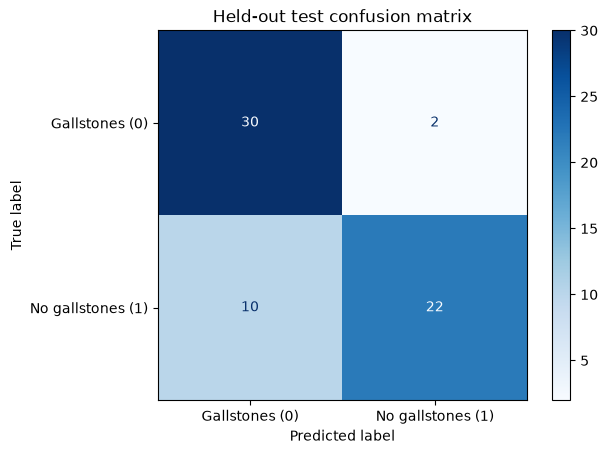

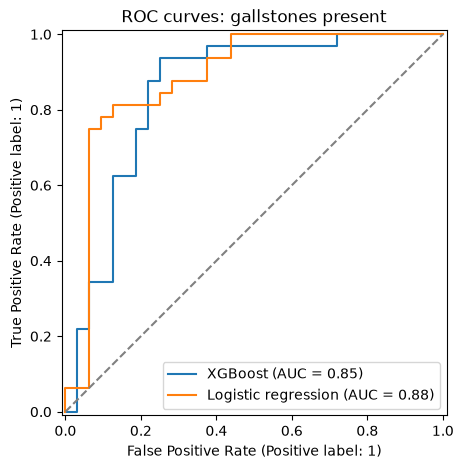

Correct cases: 30; missed cases: 2; false alarms: 10; correct controls: 22
Sensitivity: 93.8%; Specificity: 68.8%
Accuracy difference (XGBoost minus baseline): +3.1%


In [148]:
test_predictions = model.predict(X_test)
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, labels=[0, 1],
    display_labels=["Gallstones (0)", "No gallstones (1)"], cmap="Blues"
)
plt.title("Held-out test confusion matrix")
save_plot("confusion_matrix.png")

fig, ax = plt.subplots(figsize=(6, 5))
for name, estimator in models.items():
    RocCurveDisplay.from_predictions(
        y_test == 0, gallstone_probability(estimator, X_test), name=name, ax=ax
    )
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_title("ROC curves: gallstones present")
save_plot("roc_curves.png")

tp, fn, fp, tn = confusion_matrix(y_test, test_predictions, labels=[0, 1]).ravel()
print(f"Correct cases: {tp}; missed cases: {fn}; false alarms: {fp}; correct controls: {tn}")
print(f"Sensitivity: {metrics['sensitivity_gallstones']:.1%}; "
      f"Specificity: {metrics['specificity_gallstones']:.1%}")
print(f"Accuracy difference (XGBoost minus baseline): "
      f"{metrics['accuracy'] - baseline_metrics['accuracy']:+.1%}")

## 7. Explainability with SHAP
Permutation SHAP explains the class-0 probability directly, using up to 100 training records as background and the held-out records as explained samples [3,4]. This avoids reading the XGBoost internal base-score format. Positive SHAP values increase predicted gallstone probability; negative values reduce it. Mean absolute SHAP values rank features by the average magnitude of their contribution, not the direction. The approximation depends on the selected background and permutations.

In [149]:
background = X_train.sample(n=min(100, len(X_train)), random_state=42)

def predict_gallstones(values):
    """SHAP passes arrays; restore the original feature names."""
    return gallstone_probability(model, pd.DataFrame(values, columns=X_train.columns))

explainer = shap.Explainer(predict_gallstones, background,
                          algorithm="permutation", seed=42)
explanations = explainer(X_test, max_evals=5 * (2 * X_test.shape[1] + 1))

# Check that SHAP contributions add up to the predicted probability.
np.testing.assert_allclose(
    explanations.base_values + explanations.values.sum(axis=1),
    predict_gallstones(X_test), atol=1e-5
)

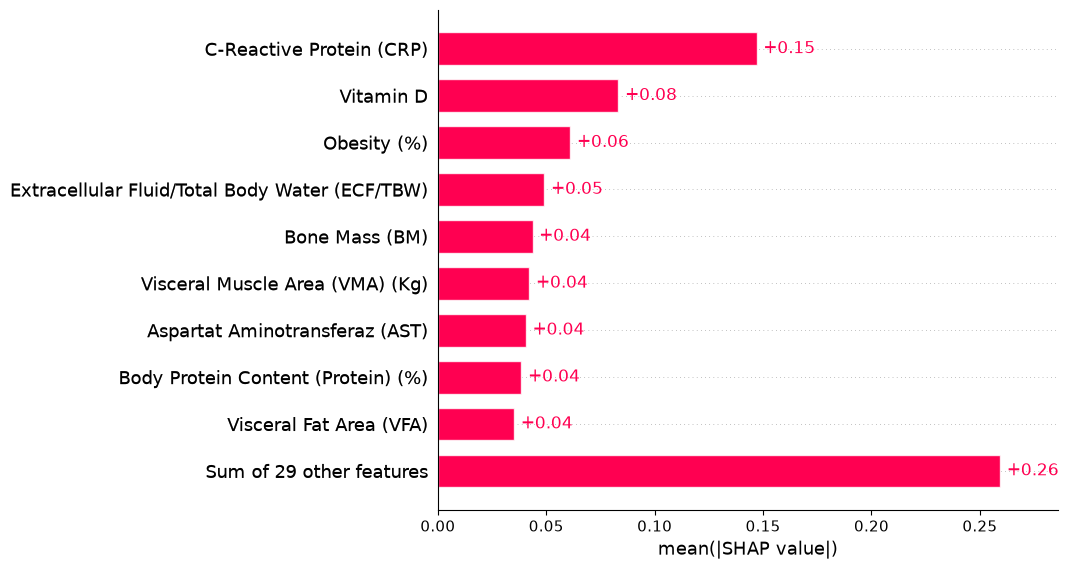

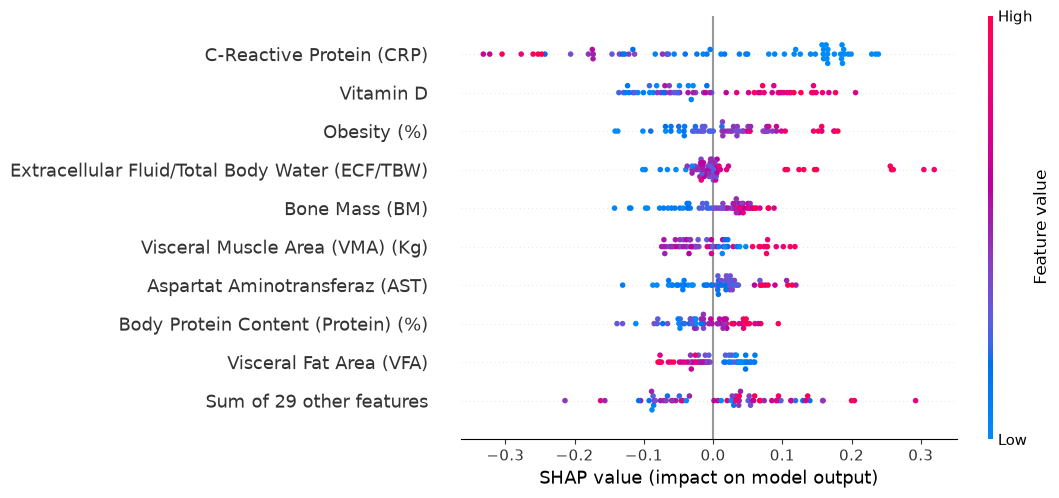

,Mean absolute SHAP
C-Reactive Protein (CRP),0.1470
Vitamin D,0.0833
Obesity (%),0.0611
Extracellular Fluid/Total Body Water (ECF/TBW),0.0492
Bone Mass (BM),0.0437
Visceral Muscle Area (VMA) (Kg),0.0422
Aspartat Aminotransferaz (AST),0.0406
Body Protein Content (Protein) (%),0.0386
Visceral Fat Area (VFA),0.0352
Hemoglobin (HGB),0.0231


Most influential features: C-Reactive Protein (CRP), Vitamin D, Obesity (%), Extracellular Fluid/Total Body Water (ECF/TBW), Bone Mass (BM)


In [150]:
shap.plots.bar(explanations, max_display=10, show=False)
save_plot("shap_bar.png")

shap.plots.beeswarm(explanations, max_display=10, show=False)
save_plot("shap_beeswarm.png")

importance = pd.Series(np.abs(explanations.values).mean(axis=0),
                       index=X_test.columns, name="Mean absolute SHAP")
importance = importance.sort_values(ascending=False)
display(importance.head(10).to_frame().round(4))
print("Most influential features:", ", ".join(importance.head(5).index))

,Feature,Low group max,High group min,Low n,High n,Low mean SHAP,High mean SHAP
0,C-Reactive Protein (CRP),0.000,1.6075,22,16,0.1675,-0.2004
1,Vitamin D,13.650,28.3750,16,16,-0.0754,0.1086
2,Obesity (%),15.975,38.0500,16,16,-0.0617,0.1119
3,Extracellular Fluid/Total Body Water (ECF/TBW),40.060,44.0000,16,20,-0.0305,0.1103
4,Bone Mass (BM),2.375,3.1000,16,19,-0.0710,0.0536


Example test record: actual class 0, predicted class 1.


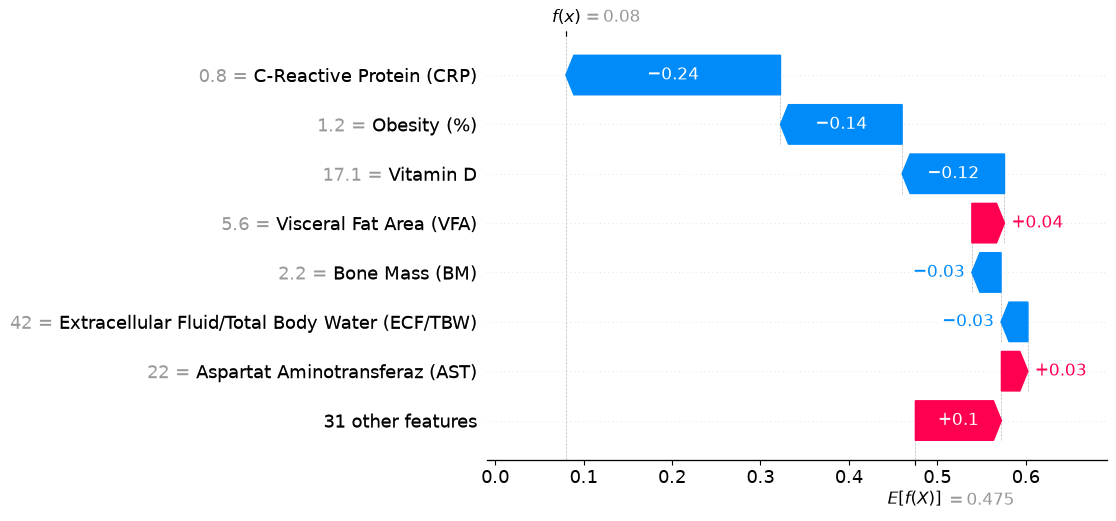

In [151]:
# Compare SHAP contributions for low and high values of the top five features.
direction_rows = []
for feature in importance.head(5).index:
    values = X_test[feature].to_numpy()
    contributions = explanations.values[:, X_test.columns.get_loc(feature)]
    low, high = np.quantile(values, [0.25, 0.75])
    if low == high:
        low, high = values.min(), values.max()
    if low == high:
        continue

    low_mask, high_mask = values <= low, values >= high
    direction_rows.append([
        feature, low, high, low_mask.sum(), high_mask.sum(),
        contributions[low_mask].mean(), contributions[high_mask].mean()
    ])

direction = pd.DataFrame(direction_rows, columns=[
    "Feature", "Low group max", "High group min", "Low n", "High n",
    "Low mean SHAP", "High mean SHAP"
])
display(direction.round(4))

# Explain a missed case, or a correctly detected case if none were missed.
missed = np.flatnonzero((y_test.to_numpy() == 0) & (test_predictions == 1))
cases = np.flatnonzero(y_test.to_numpy() == 0)
case = missed[0] if len(missed) else cases[0] if len(cases) else 0

print(f"Example test record: actual class {y_test.iloc[case]}, predicted class {test_predictions[case]}.")
shap.plots.waterfall(explanations[case], max_display=8, show=False)
save_plot("shap_waterfall.png")

## 8. Discussion and conclusion
The results address both parts of the research question. The test metrics measure how effectively the model distinguishes cases from controls, while SHAP quantifies which clinical inputs influence the model. Compare the two classifiers on the same test set and consider fold-to-fold variability before claiming one is better. The previous saved run achieved 52/64 correct classifications (81.25%), with 30/32 cases detected and 22/32 controls correctly rejected. Use the current numbers below if they differ. This earlier run did not finish SHAP, so it provides no verified feature ranking.

The SHAP bar chart ranks magnitude; the beeswarm and low/high table describe direction. A feature can be influential without always increasing the predicted probability. Correlated body-composition measures may share or redistribute importance; the observed direction is not causal. The local waterfall is one example, not representative of all patients.

**Limitations:** 319 patients from one clinic, only 64 test records, no independent validation, possible selection bias and correlated predictors. The observations classify existing disease rather than predict future incidence. Class probabilities are not necessarily calibrated clinical risks. The dataset contains clinical codes and measurements collected around the same visit; their availability at intended prediction time would need checking. A high sensitivity with lower specificity means the model may flag many controls. No clinical deployment is justified by this study alone.

The cell below writes a data-dependent summary for the report. Review the interpretations rather than treating generated sentences as proof of causal effects.

## Research question Answers

- How accurately can a machine learning model distinguisk between patients with and without gallstone discease: 
    - The XGBoost model achieved an accuracy of 81.25%, correctly classifying 52 out of the 64 patients in the test set. It correctly identified 30 out of 32 patients with gallstones, giving a sensitivity of 93.75%. For patients without gallstones, it correctly classified 22 out of 32, giving a specificity of 68.75%. This means that the model was better at identifying patients with gallstones than patients without them.

    - Logistic regression achieved an accuracy of 78.13%, which was slightly lower than XGBoost. However, logistic regression achieved a higher ROC-AUC (0.883 compared to 0.850), indicating better discrimination across different classification thresholds on this test set. Five-fold cross-validation gave an average accuracy of 76.1% for XGBoost and 74.1% for logistic regression. Overall, both models were able to distinguish between the two patient groups reasonably well, but the small dataset and lack of external validation make it difficult to conclude how well they would perform on new patient populations.  

- Which clinical charateristics contribute most to the predictions:
    - The SHAP analysis showed that C-reactive protein (CRP) had the greatest influence on the XGBoost predictions, followed by vitamin D, obesity (%), extracellular fluid/total body water (ECF/TBW), and bone mass (BM). CRP had a mean absolute SHAP value of 0.1470, compared to 0.0833 for vitamin D, 0.0611 for obesity, 0.0492 for ECF/TBW, and 0.0437 for bone mass.

    - The SHAP results also showed that lower CRP values tended to increase the predicted probability of gallstones, while higher CRP values tended to decrease it in this dataset. Higher values of vitamin D, obesity, ECF/TBW and bone mass had positive average SHAP contributions in the high-value groups. These results describe how the model uses the measurements, rather than proving that they increase or decrease the actual risk of developing gallstones. Some of the clinical measurements are correlated, which may also affect their individual importance.

## Discussion

Fix